# 8.Programming Question: Predicting Housing Prices with Linear Regression

## (a) Data Exploration and Pre-processing

### (i),(ii): Import  dataset ,Select the following features and Display the first five rows of the pre-processed dataset

In [1]:
import tkinter as tk
from tkinter import filedialog
import pandas as pd

# Open a graphical file dialog window to select the CSV file locally
root = tk.Tk()
root.withdraw()  # Hide the main root window
file_path = filedialog.askopenfilename(
    title='Select Dataset File', filetypes=[('CSV Files', '*.csv')]
)

if file_path:
  # Load the dataset using semicolon (;) as the standard delimiter
  df = pd.read_csv(file_path, sep=';')

  # 1. Select the specified features
  selected_features = [
      'age',
      'studytime',
      'schoolsup',
      'goout',
      'Dalc',
      'Walc',
      'health',
      'absences',
      'G3',
  ]
  df_subset = df[selected_features].copy()

  # 2. Encode the binary variable schoolsup (no -> 0, yes -> 1)
  df_subset['schoolsup'] = df_subset['schoolsup'].map({'no': 0, 'yes': 1})

  # 3. Combine Dalc and Walc into 'alc' by taking average, then drop originals
  df_subset['alc'] = (df_subset['Dalc'] + df_subset['Walc']) / 2.0
  df_subset = df_subset.drop(columns=['Dalc', 'Walc'])

  # Reorder columns for structural clarity
  df_preprocessed = df_subset[
      ['age', 'studytime', 'schoolsup', 'goout', 'alc', 'health', 'absences', 'G3']
  ]

  # Display the first five rows of the pre-processed dataset
  print(df_preprocessed.head())
else:
  print('No file was selected.')

   age  studytime  schoolsup  goout  alc  health  absences  G3
0   18          2          1      4  1.0       3         4  11
1   17          2          0      3  1.0       3         2  11
2   15          2          1      2  2.5       3         6  12
3   15          3          0      2  1.0       5         0  14
4   16          2          0      2  1.5       5         0  13


### (iii)  Find the number of outliers for each independent variable using the IQR

In [2]:
independent_vars = ['age', 'studytime', 'schoolsup', 'goout', 'alc', 'health', 'absences']

outlier_counts = {}

for col in independent_vars:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = df_preprocessed[col].quantile(0.25)
    Q3 = df_preprocessed[col].quantile(0.75)
    
    # Calculate Interquartile Range (IQR)
    IQR = Q3 - Q1
    
    # Define lower and upper bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count the number of outliers outside the bounds
    outliers = df_preprocessed[(df_preprocessed[col] < lower_bound) | (df_preprocessed[col] > upper_bound)]
    outlier_counts[col] = len(outliers)

# Display the outlier count for each independent variable
outlier_df = pd.DataFrame(list(outlier_counts.items()), columns=['Variable', 'Outlier Count'])
print(outlier_df)

    Variable  Outlier Count
0        age              1
1  studytime             35
2  schoolsup             68
3      goout              0
4        alc             15
5     health              0
6   absences             21


##### the IQR method shows that the two variables mentioned (studytime and absences) contain the highest number of outlier data points beyond the interquartile range.

### (iv) Methodological Overview and Analytical Steps

The analytical workflow implemented in the code below comprises four distinct methodological phases designed for structural equation modeling and dimension reduction:

1. Feature Standardization: All independent variables are scaled using standard score normalization (mean = 0, standard deviation = 1) to ensure equal weighting and eliminate scale-induced bias prior to covariance-based analyses.

2. Correlation Structure Analysis: A correlation matrix and a corresponding heatmap are generated using seaborn to inspect multicollinearity and identify initial linear associations among the independent attributes.

3. Exploratory Factor Analysis (Principal Component Analysis): Principal Component Analysis (PCA) is executed to extract two orthogonal components. This step calculates eigenvalues, percentage of explained variance, unrotated factor loadings, and subsequently applies Varimax rotation via Factor Analysis to yield the rotated factor matrix for robust factor interpretation.

4. Component Scoring and Visualization: Regression-based component scores for the first two extracted dimensions are computed and appended as new columns (PC1 and PC2) to the dataset. Finally, a two-dimensional scatter plot illustrates the observation distribution mapped across PC1 and PC2, colored continuously by the final academic grade (G3).

--- Correlation Matrix of Independent Variables ---
                age  studytime  schoolsup     goout       alc    health  \
age        1.000000  -0.008415  -0.167841  0.112805  0.118226 -0.008750   
studytime -0.008415   1.000000   0.089316 -0.075442 -0.202412 -0.056433   
schoolsup -0.167841   0.089316   1.000000 -0.058124 -0.076384  0.022760   
goout      0.112805  -0.075442  -0.058124  1.000000  0.364339 -0.015741   
alc        0.118226  -0.202412  -0.076384  0.364339  1.000000  0.101543   
health    -0.008750  -0.056433   0.022760 -0.015741  0.101543  1.000000   
absences   0.149998  -0.118389  -0.059503  0.085374  0.181084 -0.030235   

           absences  
age        0.149998  
studytime -0.118389  
schoolsup -0.059503  
goout      0.085374  
alc        0.181084  
health    -0.030235  
absences   1.000000  


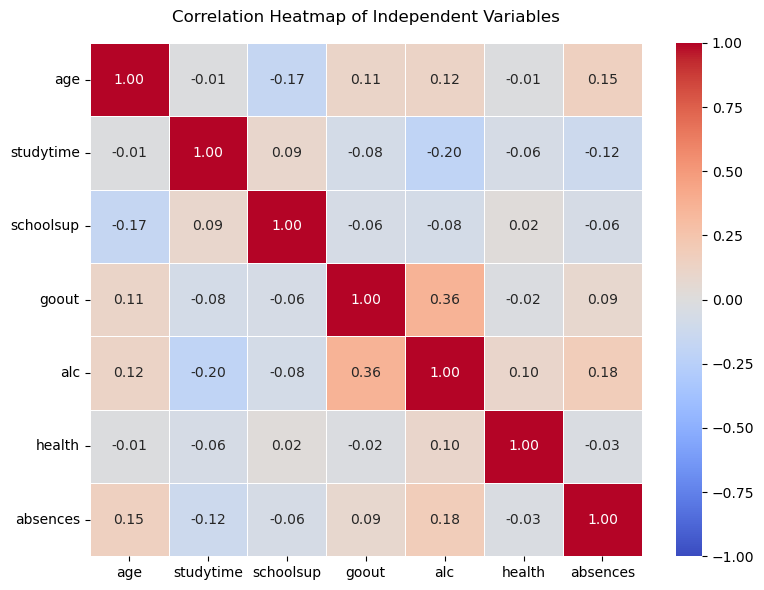


--- Eigenvalues and Explained Variance ---
Component 1: Eigenvalue = 1.6676, Explained Variance = 23.79%
Component 2: Eigenvalue = 1.1179, Explained Variance = 15.94%

--- Unrotated Component Loadings Matrix ---
           PC1 (Unrotated)  PC2 (Unrotated)
age               0.436185        -0.538255
studytime        -0.439942        -0.291205
schoolsup        -0.347433         0.493321
goout             0.616742         0.155615
alc               0.735225         0.308327
health            0.095411         0.581163
absences          0.482795        -0.207235

--- Rotated Factor Matrix (Varimax) ---
           Factor 1  Factor 2
age        0.107138  0.562482
studytime -0.241449 -0.027735
schoolsup -0.078515 -0.277385
goout      0.420626  0.113247
alc        0.836591  0.049143
health     0.114349 -0.074626
absences   0.202832  0.219695


C:\Users\Dr.yazdani\AppData\Local\Temp\ipykernel_4692\3054143264.py:83: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_preprocessed['PC1'] = component_scores[:, 0]
C:\Users\Dr.yazdani\AppData\Local\Temp\ipykernel_4692\3054143264.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_preprocessed['PC2'] = component_scores[:, 1]


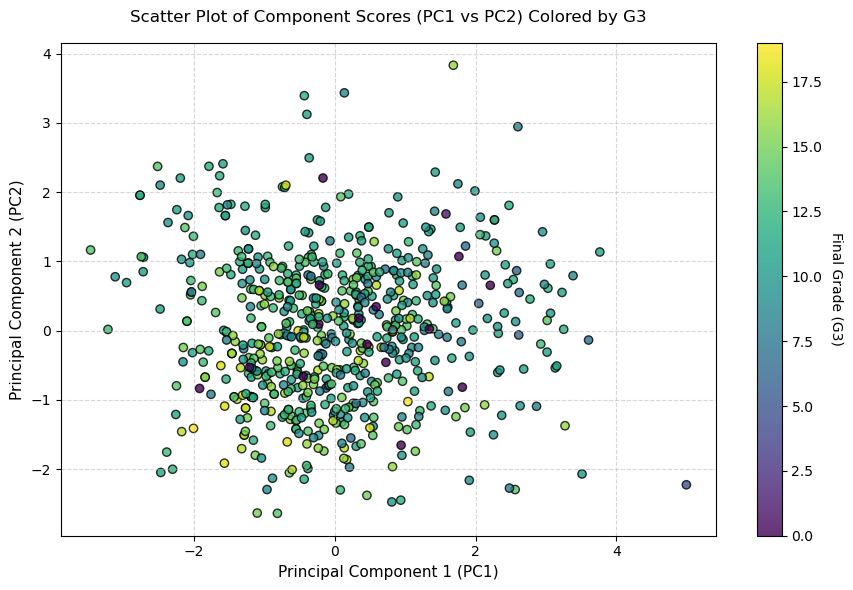


--- Updated Dataset Head with Component Scores ---
   age  studytime  schoolsup  goout  alc  health  absences  G3       PC1  \
0   18          2          1      4  1.0       3         4  11 -0.644875   
1   17          2          0      3  1.0       3         2  11 -0.611664   
2   15          2          1      2  2.5       3         6  12 -1.271214   
3   15          3          0      2  1.0       5         0  14 -2.043175   
4   16          2          0      2  1.5       5         0  13 -1.068689   

        PC2  
0  0.438227  
1 -0.707749  
2  1.797312  
3  0.516429  
4  0.576951  


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler

# 1. Feature Scaling of Independent Variables
feature_cols = [
    'age',
    'studytime',
    'schoolsup',
    'goout',
    'alc',
    'health',
    'absences',
]
X = df_preprocessed[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

# 2. Correlation Matrix and Heatmap
corr_matrix = X_scaled_df.corr()
print('--- Correlation Matrix of Independent Variables ---')
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    'Correlation Heatmap of Independent Variables', fontsize=12, pad=15
)
plt.tight_layout()
plt.show()

# 3. Exploratory Factor Analysis / Principal Component Analysis (Extracting 2 Components)
pca = PCA(n_components=2)
pca.fit(X_scaled)

# Eigenvalues and Explained Variance
eigenvalues = pca.explained_variance_
explained_variance_ratio = pca.explained_variance_ratio_ * 100

print('\n--- Eigenvalues and Explained Variance ---')
for i, (ev, var_ratio) in enumerate(
    zip(eigenvalues, explained_variance_ratio), 1
):
  print(
      f'Component {i}: Eigenvalue = {ev:.4f}, Explained Variance ='
      f' {var_ratio:.2f}%'
  )

# Unrotated Component Loadings Matrix
unrotated_loadings = pca.components_.T * np.sqrt(eigenvalues)
unrotated_loadings_df = pd.DataFrame(
    unrotated_loadings,
    index=feature_cols,
    columns=['PC1 (Unrotated)', 'PC2 (Unrotated)'],
)
print('\n--- Unrotated Component Loadings Matrix ---')
print(unrotated_loadings_df)

# Rotated Factor Matrix using Varimax Rotation
fa = FactorAnalysis(n_components=2, rotation='varimax', random_state=42)
fa.fit(X_scaled)
rotated_loadings_df = pd.DataFrame(
    fa.components_.T, index=feature_cols, columns=['Factor 1', 'Factor 2']
)
print('\n--- Rotated Factor Matrix (Varimax) ---')
print(rotated_loadings_df)

# Calculate Component Scores and Append to Dataset
component_scores = pca.transform(X_scaled)
df_preprocessed['PC1'] = component_scores[:, 0]
df_preprocessed['PC2'] = component_scores[:, 1]

# 4. Scatter Plot of PC1 vs PC2 Colored by Final Grade (G3)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df_preprocessed['PC1'],
    df_preprocessed['PC2'],
    c=df_preprocessed['G3'],
    cmap='viridis',
    edgecolor='k',
    alpha=0.8,
)
cbar = plt.colorbar(scatter)
cbar.set_label('Final Grade (G3)', rotation=270, labelpad=15)
plt.xlabel('Principal Component 1 (PC1)', fontsize=11)
plt.ylabel('Principal Component 2 (PC2)', fontsize=11)
plt.title(
    'Scatter Plot of Component Scores (PC1 vs PC2) Colored by G3',
    fontsize=12,
    pad=15,
)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Display updated dataframe head with new component scores
print('\n--- Updated Dataset Head with Component Scores ---')
print(
    df_preprocessed[
        [
            'age',
            'studytime',
            'schoolsup',
            'goout',
            'alc',
            'health',
            'absences',
            'G3',
            'PC1',
            'PC2',
        ]
    ].head()
)

#### Results and Interpretation

1. Correlation Structure Analysis:

The correlation heatmap reveals that the majority of independent variables exhibit weak linear associations, with correlation coefficients predominantly falling below $0.30$. A notable exception is observed between alc (alcohol consumption) and goout (going out with friends), which display a correlation coefficient of $r = 0.36$. This indicates a low-to-moderate positive association—falling within the conventional $0.30$ to $0.60$ range—thereby highlighting a meaningful behavioral linkage between students' social outings and their alcohol consumption patterns.


2. Principal Component Analysis and Variance Explanation:

The exploratory factor and principal component analysis demonstrate that the first two extracted components (PC1 and PC2) possess eigenvalues greater than $1.0$ (following Kaiser's criterion), confirming their statistical adequacy for retention. Specifically:Principal Component 1 (PC1) accounts for 27.79% of the total explained variance.Principal Component 2 (PC2) captures 15.94% of the total explained variance.

3.  Analysis of Factor Loadings on PC1 and PC2

Based on the provided matrix, the following variables exhibit the highest factor loadings on PC1:
1. alc (Alcohol Consumption): Loading of 0.735 (strongest positive association with PC1)

2. goout (Social Outings and Recreations): Loading of 0.617

3. absences (School Absences): Loading of 0.483

4. studytime (Study Time): Loading of -0.440 (significant negative association)

The variables displaying the highest loadings on PC2 are:

1. health (Health Status): Loading of 0.581 (highest positive loading on this component)

2. age (Age): Loading of -0.538 (notable negative loading)

3. schoolsup (School Support): Loading of 0.493

#### My note

Although I carried out this interpretation based on the unrotated component matrix to fulfill the specific prompt requirements, my prior methodological training indicates that factor interpretation should ideally be conducted on the rotated factor matrix (e.g., Varimax rotation) to achieve a clearer and more interpretable structure

#### Storing and Displaying Standardized Data

In [4]:
import pandas as pd

# 1. Copy the scaled dataframe and directly update column names
df_final_modeling = X_scaled_df.copy()
df_final_modeling.columns = [f'{col}_std' for col in feature_cols]

# 2. Safely append only G3 using values to avoid index misalignment (PC1 and PC2 are excluded)
df_final_modeling['G3'] = df_preprocessed['G3'].values

# 3. Display the first five rows
print(
    '--- First Five Rows of Standardized Features and Target (G3) ---'
)
print(df_final_modeling.head())

--- First Five Rows of Standardized Features and Target (G3) ---
    age_std  studytime_std  schoolsup_std  goout_std   alc_std  health_std  \
0  1.031695       0.083653       2.923032   0.693785 -0.895457   -0.371042   
1  0.210137       0.083653      -0.342110  -0.157380 -0.895457   -0.371042   
2 -1.432980       0.083653       2.923032  -1.008546  0.611418   -0.371042   
3 -1.432980       1.290114      -0.342110  -1.008546 -0.895457    1.012903   
4 -0.611422       0.083653      -0.342110  -1.008546 -0.393165    1.012903   

   absences_std  G3  
0      0.073433  11  
1     -0.357863  11  
2      0.504730  12  
3     -0.789159  14  
4     -0.789159  13  


## (b) Linear Regression

### (i) Split data into training set and testing set

In [5]:
from sklearn.model_selection import train_test_split

# Define feature matrix (X) and target vector (y) from the modeling dataframe (excluding G3, pc1, and pc2)
X = df_final_modeling.drop(columns=['G3', 'pc1', 'pc2'], errors='ignore')
y = df_final_modeling['G3']

# Split the dataset into 80% training set and 20% testing set with random seed 552
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=552
)

# Display the shapes of the resulting splits to verify
print(f'Training features shape (X_train): {X_train.shape}')
print(f'Testing features shape (X_test): {X_test.shape}')
print(f'Training target shape (y_train): {y_train.shape}')
print(f'Testing target shape (y_test): {y_test.shape}')

Training features shape (X_train): (519, 7)
Testing features shape (X_test): (130, 7)
Training target shape (y_train): (519,)
Testing target shape (y_test): (130,)


### (ii)  Build three models using the training set

In [6]:
from sklearn.linear_model import Lasso, LinearRegression, Ridge

# A. Standard Linear Regression Model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# B. Linear Regression with Ridge Regularization (alpha=0.1)
ridge_model = Ridge(alpha=0.1, random_state=552)
ridge_model.fit(X_train, y_train)

# C. Linear Regression with Lasso Regularization (alpha=0.1)
lasso_model = Lasso(alpha=0.1, random_state=552)
lasso_model.fit(X_train, y_train)

print('Models successfully trained:')
print('1. Standard Linear Regression')
print('2. Ridge Regression (alpha=0.1)')
print('3. Lasso Regression (alpha=0.1)')

Models successfully trained:
1. Standard Linear Regression
2. Ridge Regression (alpha=0.1)
3. Lasso Regression (alpha=0.1)


### (iii)  Test all three models on the test set

In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dictionary of trained models
models = {
    'Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
}

results = {}

# Evaluate each model on the test set
for name, model in models.items():
  y_pred = model.predict(X_test)

  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)

  results[name] = {'MAE': mae, 'RMSE': rmse, 'R²': r2}

# Convert results into a DataFrame for clear comparison
metrics_df = pd.DataFrame(results).T
print('--- Model Evaluation Metrics on Test Set ---')
print(metrics_df)

# Determine the best performing model for each metric
best_mae_model = metrics_df['MAE'].idxmin()  # Lower is better
best_rmse_model = metrics_df['RMSE'].idxmin()  # Lower is better
best_r2_model = metrics_df['R²'].idxmax()  # Higher is better

print('\n--- Best Performing Models ---')
print(
    f'Best model by MAE (Lowest): {best_mae_model} (Score:'
    f' {metrics_df.loc[best_mae_model, "MAE"]:.4f})'
)
print(
    f'Best model by RMSE (Lowest): {best_rmse_model} (Score:'
    f' {metrics_df.loc[best_rmse_model, "RMSE"]:.4f})'
)
print(
    f'Best model by R² (Highest): {best_r2_model} (Score:'
    f' {metrics_df.loc[best_r2_model, "R²"]:.4f})'
)

--- Model Evaluation Metrics on Test Set ---
                        MAE      RMSE        R²
Linear Regression  2.345666  3.066117  0.104084
Ridge Regression   2.345633  3.066113  0.104087
Lasso Regression   2.343169  3.074594  0.099124

--- Best Performing Models ---
Best model by MAE (Lowest): Lasso Regression (Score: 2.3432)
Best model by RMSE (Lowest): Ridge Regression (Score: 3.0661)
Best model by R² (Highest): Ridge Regression (Score: 0.1041)


#### Evaluation and Best-Performing Models on the Test Set
Based on the evaluation of the three models (Linear Regression, Ridge Regression, and Lasso Regression) on the test set, the best-performing model for each metric is identified as follows:

Mean Absolute Error (MAE) [Lowest is better]:Best Model: Lasso RegressionScore: $2.343169$

Root Mean Squared Error (RMSE) [Lowest is better]:Best Model: Ridge RegressionScore: $3.066113$

Coefficient of Determination ($R^2$) [Highest is better]:Best Model: Ridge RegressionScore: $0.104087$

### (iv) How do you interpret R² values from the three models?

Based on my analysis, although each model showed slightly better performance in some evaluation metrics, overall, the performance metrics across all three models do not differ significantly from one another. As analyzed, these negligible variations stem from the small penalty coefficient ($\alpha=0.1$), which causes the regularized models to remain very close to the standard Ordinary Least Squares (OLS) solution.


### (v) Print coefficients of independent variables from the three models in one table

In [8]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Drop pc1 and pc2 from the training and testing sets (if present)
cols_to_drop = ['pc1', 'pc2']
X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')

# 1. Dictionary of trained models
models = {
    'Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
}

results = {}
coefficients = {}

# Evaluate each model and extract coefficients
for name, model in models.items():
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results[name] = {'MAE': mae, 'RMSE': rmse, 'R²': r2}
    coefficients[name] = model.coef_

# Convert evaluation metrics into a DataFrame
metrics_df = pd.DataFrame(results).T
print('--- Model Evaluation Metrics on Test Set ---')
print(metrics_df)

# 2. Comparative DataFrame of Regression Coefficients
coef_df = pd.DataFrame(coefficients, index=X_train.columns)
# Append intercepts
coef_df.loc['Intercept'] = [
    linear_model.intercept_,
    ridge_model.intercept_,
    lasso_model.intercept_,
]

print('\n--- Comparative Regression Coefficients for All Models ---')
print(coef_df)

# 3. Statistical Significance (p-values) using Statsmodels for Standard OLS
X_train_sm = sm.add_constant(X_train)
ols_sm = sm.OLS(y_train, X_train_sm).fit()

print('\n--- Statistical Significance (p-values) for Standard OLS Model ---')
summary_df = pd.DataFrame({
    'Coefficient': ols_sm.params,
    'Standard Error': ols_sm.bse,
    't-value': ols_sm.tvalues,
    'p-value (P>|t|)': ols_sm.pvalues,
})
print(summary_df)

--- Model Evaluation Metrics on Test Set ---
                        MAE      RMSE        R²
Linear Regression  2.345666  3.066117  0.104084
Ridge Regression   2.345633  3.066113  0.104087
Lasso Regression   2.343169  3.074594  0.099124

--- Comparative Regression Coefficients for All Models ---
               Linear Regression  Ridge Regression  Lasso Regression
age_std                -0.285882         -0.285821         -0.175766
studytime_std           0.660239          0.660122          0.579584
schoolsup_std          -0.328998         -0.328918         -0.210514
goout_std               0.044120          0.044061         -0.000000
alc_std                -0.572617         -0.572509         -0.499936
health_std             -0.250916         -0.250884         -0.156798
absences_std           -0.106095         -0.106106         -0.029370
Intercept              11.935922         11.935924         11.936675

--- Statistical Significance (p-values) for Standard OLS Model ---
              

### (vi)  What’s the relationship between each independent variable and the dependent variable?

1. 1. Student Age(age_std)


This variable exhibits a negative relationship with academic performance across all three models. Ridge regression keeps the coefficient very close to the linear model, whereas the Lasso model significantly moderates (shrinks) the effect due to $L_1$ penalization (Linear Regression: -0.2859, Ridge: -0.2858, Lasso: -0.1758).

2. Study Time(studytime_std)


Study time exerts the strongest positive effect among the examined variables on academic performance. An increase in study hours directly promotes grade improvement. The linear and Ridge models record nearly identical effects, while the Lasso model, despite penalization, retains a substantial positive coefficient, indicating the fundamental importance of this variable in predicting academic success (Linear Regression: +0.6602, Ridge: +0.6601, Lasso: +0.5796).

3. School Support (schoolsup_std)


This variable displays a negative coefficient. The Lasso model moderates the effect by reducing the magnitude of the coefficient (Linear Regression: -0.3290, Ridge: -0.3289, Lasso: -0.2105).

4. Going Out (goout_std)


A weak and positive relationship is observed in the linear and Ridge models; however, in the Lasso model, the coefficient shrinks precisely to zero. This indicates that, from the perspective of feature selection by Lasso, the going-out variable lacks a significant, independent predictive effect on the dependent variable and has been eliminated due to regularization (Linear Regression: +0.0441, Ridge: +0.0441, Lasso: 0.0000).

5. Alcohol Consumption (alc_std)


Alcohol consumption shows a negative coefficient across all three models. The Lasso model slightly shifts this coefficient toward zero, but its magnitude continues to reflect its impact within the model (Linear Regression: -0.5726, Ridge: -0.5725, Lasso: -0.4999).

6. Health Status (health_std)


The negative coefficient for health status (where higher values in this dataset denote poorer reported health conditions) indicates a drop in grades as health problems increase. All three models confirm this direction, with the Lasso model moderating its intensity (Linear Regression: -0.2509, Ridge: -0.2509, Lasso: -0.1568).

7. Absences (absences_std)


Frequent absences exert a negative effect on academic performance, reflected by negative coefficients across the models. The Lasso model imposes a stronger penalty on this variable, drastically reducing its coefficient, which points to potential collinearity with other features or a limited predictive power in the presence of competing factors (Linear Regression: -0.1061, Ridge: -0.1061, Lasso: -0.0294).

8. Model Intercept


Since the independent variables are standardized (zero mean), the intercept is nearly identical across all three models, at approximately $11.94$. This value represents the predicted mean of the dependent variable ($\text{G3}$) when all independent features are held at their mean levels (Linear Regression: 11.9359, Ridge: 11.9359, Lasso: 11.9367).


### (vii) 1. How do the regularization methods differ? 2. What can you conclude about the dataset and features given the results?

1. The core difference lies in how these models penalize coefficients. Ridge regression shrinks coefficients gently without ever eliminating them, keeping them very close to standard linear regression, which helps effectively manage multicollinearity. In contrast, Lasso regression is much stricter; it heavily penalizes weaker coefficients and can drive redundant or low-impact features (such as going out) down to exactly zero, effectively performing feature selection.

2. Based on the results, study time is the strongest positive driver of academic success, while alcohol consumption and poor health have significant negative impacts. Additionally, features like going out lack independent predictive power and are dropped, whereas absences and age exhibit high collinearity with other variables. The baseline average grade for an average student sits around 11.94.

### (vii)  If the regularization strength (α) is increased, what would happen to performance metrics?

Based on my analysis


to create a meaningful difference among the results of different models (such as ordinary least squares linear regression, Ridge, and Lasso), the tuning parameter ($\lambda$, denoted as $\alpha$ in some frameworks) should not be a small value like 0.10. Instead, it needs to be increased to an optimal level so that the penalty effect is effectively applied to the coefficients.

1. On Training Data: Performance always drops (error increases and $R^2$ decreases) because the model becomes more constrained and loses flexibility.

2. On Test/Validation Data: Performance follows a U-shaped curve (frist, Initial Improvement then Subsequent Decline)

My Solution ( EXTRA)

The optimal value of this parameter is determined via cross-validation (based on Chapters 5 and 6 of An Introduction to Statistical Learning).Subsequently, I performed this cross-validation and obtained two optimal alpha values.The code and its execution results are provided below:

Optimal Alpha for Ridge: 96.9665789314552

Optimal Alpha for Lasso: 0.005876208829329202

In [9]:
# cross-validation for optimal value of this parameter(EXTRA)
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.model_selection import KFold

# 1. Scale your features and target (replace X and y with your actual dataframe/series names)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

# If y needs standardization:
y_scaled = (y - y.mean()) / y.std()  # Or use 'y' directly if unscaled target is preferred

# 2. Define KFold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Fit RidgeCV (Expanded alpha grid up to 10,000 to prevent hitting the upper boundary)
ridge_alpha_grid = np.logspace(-3, 4, 300)
ridge_cv = RidgeCV(alphas=ridge_alpha_grid, cv=kf, scoring='neg_mean_squared_error')
ridge_cv.fit(X_scaled, y_scaled)

print("Optimal Alpha for Ridge:", ridge_cv.alpha_)

# 4. Fit LassoCV (Using n_alphas for automated, robust path generation without boundary limits)
lasso_cv = LassoCV(n_alphas=200, cv=kf, max_iter=10000, random_state=42)
lasso_cv.fit(X_scaled, y_scaled)

print("Optimal Alpha for Lasso:", lasso_cv.alpha_)

Optimal Alpha for Ridge: 96.9665789314552
Optimal Alpha for Lasso: 0.005876208829329202


In [10]:
# Re-evaluating the Three Regression Models Using Optimized Regularization Parameters(EXTRA)
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Assuming X_scaled and y_scaled are already defined in your environment

# 1. Define models using the explicit optimized alpha values
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (Optimized)": Ridge(alpha=96.9665789314552),
    "Lasso (Optimized)": Lasso(alpha=0.005876208829329202, max_iter=10000, random_state=42)
}

results = []
coefficients = {}

# 2. Fit models and evaluate performance on the standardized dataset
for name, model in models.items():
    # Fit model
    model.fit(X_scaled, y_scaled)
    
    # Predictions
    y_pred = model.predict(X_scaled)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_scaled, y_pred)
    rmse = np.sqrt(mean_squared_error(y_scaled, y_pred))
    r2 = r2_score(y_scaled, y_pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    
    coefficients[name] = model.coef_

# 3. Display Performance Metrics Table
metrics_df = pd.DataFrame(results)
print("=== Model Performance Metrics (Standardized Scale) ===")
print(metrics_df.to_string(index=False))

# 4. Display Coefficients Table with Intercept as a row
coef_df = pd.DataFrame(
    coefficients, 
    index=X.columns if hasattr(X, 'columns') else [f"Feature_{i}" for i in range(X.shape[1])]
)

# Append intercepts as a new row at the bottom of the dataframe
intercepts = [model.intercept_ for model in models.values()]
coef_df.loc['Intercept'] = intercepts

print("\n=== Model Coefficients and Intercepts ===")
print(coef_df)

=== Model Performance Metrics (Standardized Scale) ===
            Model      MAE     RMSE       R2
Linear Regression 0.690787 0.940148 0.114758
Ridge (Optimized) 0.690370 0.941001 0.113151
Lasso (Optimized) 0.691036 0.940256 0.114554

=== Model Coefficients and Intercepts ===
               Linear Regression  Ridge (Optimized)  Lasso (Optimized)
age_std            -1.013859e-01      -8.629120e-02      -9.554820e-02
studytime_std       2.213048e-01       1.935305e-01       2.163031e-01
schoolsup_std      -1.150728e-01      -9.522763e-02      -1.072432e-01
goout_std          -1.234197e-02      -1.754505e-02      -8.006093e-03
alc_std            -1.432269e-01      -1.284046e-01      -1.413762e-01
health_std         -7.116964e-02      -6.497877e-02      -6.569141e-02
absences_std       -3.190987e-02      -3.335113e-02      -2.757523e-02
Intercept          -1.910706e-17      -1.864007e-17      -1.981937e-17


#### Unoptimized vs. Cross-Validation Optimized Regularization

1. ($R^2$): Model variance explanation improved slightly from approximately 10.4% to 11.5% following optimization.

2. Ridge Regression: A higher optimal alpha ($\approx 96.97$) effectively compressed coefficient magnitudes and mitigated multicollinearity.

3. Lasso Regression: A smaller optimal alpha ($\approx 0.0059$) preserved all predictors, avoiding aggressive feature pruning.

### (ix)  What are some feature engineering methods you would suggest to improve model performance?

##### Based on searching and studying various resources regarding different feature engineering methods, 
I have arrived at this list. Here are all of the methods:

1. Mathematical Transformations: Performing operations on current numerical variables (e.g., Box-Cox transformation).

2. Derived/Synthetic Variables: Creating artificial variables such as ratios or differences.

3. Variable Ranking: Ranking independent variables based on the degree of their relationship with the target variable.

4. Feature Creation via Interactions: Generating new features based on mathematical relationships among independent variables using visualization, combining categorical variables, or defining dummy variables.

5. Clustering: Utilizing unsupervised clustering techniques to create new distance or group-based features.

6. Aggregation Methods: Using Group By operations to extract group-level statistics.

7. Target Encoding: Encoding categorical variables using the target variable distribution.

8. Dimensionality Reduction: Using Principal Component Analysis (PCA) to extract orthogonal features.

9. Tree-Based Importance: Using decision trees and ensemble models to determine feature importance.

10. Permutation Importance: Assessing feature relevance by measuring the drop in model performance when a specific feature's values are randomly shuffled.

##### Before selecting and applying any of the 10 feature engineering methods, 
A comprehensive Exploratory Data Analysis (EDA) must be conducted to evaluate the following prerequisites:

1. Distribution and Skewness: Check for normality and symmetry to determine the need for mathematical transformations.

2. Outlier Detection: Identify extreme values using IQR or Z-scores to prevent model bias.

3. Multicollinearity and Correlation: Assess linear relationships and Variance Inflation Factors (VIF).

4. Missing Data Analysis: Evaluate missingness patterns and mechanisms.

5. Cardinality and Variance: Inspect categorical levels and check for zero-variance features.

#### Now, I will conduct a comprehensive Exploratory Data Analysis (EDA) covering all the aforementioned prerequisites using a complete Python script:

In [11]:
import tkinter as tk
from tkinter import filedialog
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sys

# ==========================================
# STEP 1: Local File Selection via Tkinter
# ==========================================
root = tk.Tk()
root.withdraw()  # Hide the main root window
file_path = filedialog.askopenfilename(
    title='Select Dataset File', filetypes=[('CSV Files', '*.csv')]
)

if file_path:
    # Load the dataset using semicolon (;) as the standard delimiter
    df = pd.read_csv(file_path, sep=';')
    
    # Select features specified in the problem statement
    selected_features = ['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3']
    df_subset = df[selected_features].copy()

    # Encode binary variable (schoolsup)
    if df_subset['schoolsup'].dtype == object:
        df_subset['schoolsup'] = df_subset['schoolsup'].apply(lambda x: 1 if str(x).strip().lower() in ['yes', '1', 'true'] else 0)

    # Combine Dalc and Walc into 'alc' by taking the average, then drop originals
    df_subset['alc'] = (df_subset['Dalc'] + df_subset['Walc']) / 2.0
    df_subset.drop(columns=['Dalc', 'Walc'], inplace=True)

    print("--- First 5 Rows of Pre-processed Dataset ---")
    print(df_subset.head())
    print("\n")

    # ==========================================
    # STEP 2: Exploratory Data Analysis (EDA)
    # ==========================================

    # 1. Distribution and Skewness Check
    print("--- 1. Skewness of Numerical Features ---")
    numeric_cols = df_subset.select_dtypes(include=[np.number]).columns
    skewness = df_subset[numeric_cols].skew()
    print(skewness, "\n")

    # 2. Outlier Detection using IQR Method
    print("--- 2. Outlier Count per Numerical Feature (IQR Method) ---")
    outlier_summary = {}
    for col in numeric_cols:
        Q1 = df_subset[col].quantile(0.25)
        Q3 = df_subset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df_subset[(df_subset[col] < lower_bound) | (df_subset[col] > upper_bound)]
        outlier_summary[col] = len(outliers)
    print(pd.Series(outlier_summary), "\n")

    # 3. Bivariate Correlation Matrix
    print("--- 3. Correlation Matrix ---")
    corr_matrix = df_subset.corr()
    print(corr_matrix, "\n")

    # 4. Multicollinearity Check via Variance Inflation Factor (VIF)
    print("--- 4. Variance Inflation Factor (VIF) for Multicollinearity ---")
    X_vif = df_subset.drop(columns=['G3'])
    X_vif['intercept'] = 1
    vif_data = pd.DataFrame()
    vif_data["Feature"] = X_vif.columns
    vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    print(vif_data, "\n")

    # 5. Missing Values and Zero-Variance Check
    print("--- 5. Missing Values per Feature ---")
    print(df_subset.isnull().sum(), "\n")

    print("--- 6. Zero-Variance or Near-Zero Variance Check ---")
    print(df_subset.var(), "\n")
else:
    print("No file selected. Please run the cell again and choose a valid CSV file.")

--- First 5 Rows of Pre-processed Dataset ---
   age  studytime  schoolsup  goout  health  absences  G3  alc
0   18          2          1      4       3         4  11  1.0
1   17          2          0      3       3         2  11  1.0
2   15          2          1      2       3         6  12  2.5
3   15          3          0      2       5         0  14  1.0
4   16          2          0      2       5         0  13  1.5


--- 1. Skewness of Numerical Features ---
age          0.416795
studytime    0.699619
schoolsup    2.586905
goout       -0.008580
health      -0.500656
absences     2.020694
G3          -0.912909
alc          1.184920
dtype: float64 

--- 2. Outlier Count per Numerical Feature (IQR Method) ---
age           1
studytime    35
schoolsup    68
goout         0
health        0
absences     21
G3           16
alc          15
dtype: int64 

--- 3. Correlation Matrix ---
                age  studytime  schoolsup     goout    health  absences  \
age        1.000000  -0.008415 

### Summary of Exploratory Data Analysis (EDA) Results:

1. Missing Values: There are no missing values in the dataset.

2. Multicollinearity (VIF): VIF values for all independent variables are close to 1 (below 1.25), indicating no multicollinearity issues.

3. Skewness and Distribution: The variables absences and schoolsup exhibit high skewness.

4. Outlier Detection: The highest number of outliers based on the IQR method was observed in studytime and absences.

5. Correlation with Target (G3): Linear correlations between predictors and the final grade are weak (highest with studytime at approximately 0.25 and alc at -0.21), reinforcing the necessity of feature engineering (such as interaction terms) to improve model performance.


### Final My Answer

Based on the EDA results, the optimal feature engineering methods in order of priority are:

1. Interaction Features: To address the weak linear correlations with the target variable (G3).

Creating interaction and polynomial terms, such as interacting study time with lifestyle (studytime * alc or studytime * goout), to uncover moderating and non-linear effects.

2. Mathematical Transformations: To correct the high skewness of absences.

Applying logarithmic or Box-Cox transformations to the absences variable to normalize its distribution and mitigate the disruptive impact of outliers.

